# 02 Dimension reduction: PCA on the routine lab panel

Fitted on the training split only. Inputs are the latest value of each lab that is measured routinely
(under 30% missing in training); rarely ordered labs such as blood gases would be mostly imputed values.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.metrics import average_precision_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from icu_forecast.config import ROOT, load_config
from icu_forecast.prepare import load_features

cfg = load_config()
FIG = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

train = load_features(cfg).query("split == 'train'")
last_cols = [c for c in train.columns if c.endswith("_last")]
missing = train[last_cols].isna().mean().sort_values()
panel = missing[missing < 0.30].index.tolist()
print("missing share of latest lab value (train):\n", missing.round(3))
print(f"\nPCA inputs ({len(panel)}):", [c.replace('_last', '') for c in panel])

missing share of latest lab value (train):
 hemoglobin_last     0.167
platelets_last      0.167
wbc_last            0.167
creatinine_last     0.186
potassium_last      0.189
bun_last            0.189
sodium_last         0.190
chloride_last       0.190
glucose_last        0.192
bicarbonate_last    0.192
anion_gap_last      0.192
magnesium_last      0.227
calcium_last        0.235
inr_last            0.430
bilirubin_last      0.488
albumin_last        0.615
lactate_last        0.813
ph_last             0.888
troponin_t_last     0.902
po2_last            0.902
pco2_last           0.902
dtype: float64

PCA inputs (13): ['hemoglobin', 'platelets', 'wbc', 'creatinine', 'potassium', 'bun', 'sodium', 'chloride', 'glucose', 'bicarbonate', 'anion_gap', 'magnesium', 'calcium']


      explained  cumulative
PC1       0.194       0.194
PC2       0.129       0.323
PC3       0.119       0.441
PC4       0.096       0.537
PC5       0.084       0.621
PC6       0.076       0.696
PC7       0.069       0.766
PC8       0.063       0.829
PC9       0.055       0.884
PC10      0.049       0.933
PC11      0.036       0.969
PC12      0.026       0.995
PC13      0.005       1.000

components for 80%: 8, for 90%: 10, eigenvalue > 1 (Kaiser): 5


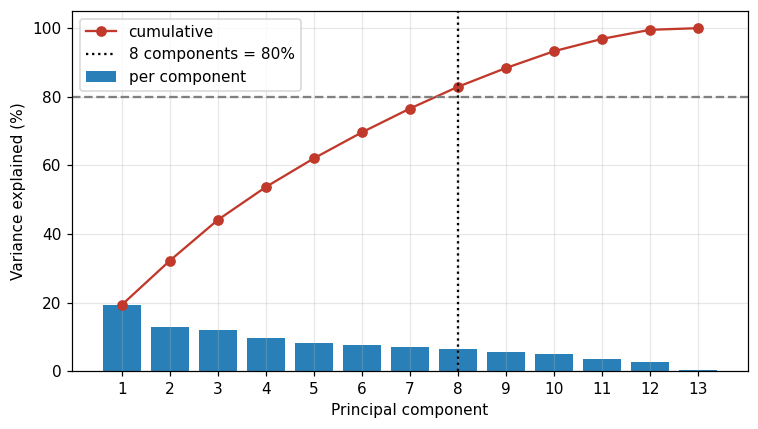

In [2]:
pca_pipe = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), PCA(random_state=cfg["seed"]))
scores = pca_pipe.fit_transform(train[panel])
pca = pca_pipe[-1]
ev = pca.explained_variance_ratio_
cum = ev.cumsum()
k80, k90 = int(np.argmax(cum >= 0.80) + 1), int(np.argmax(cum >= 0.90) + 1)
kaiser = int((pca.explained_variance_ > 1).sum())
print(pd.DataFrame({"explained": ev, "cumulative": cum}, index=[f"PC{i+1}" for i in range(len(ev))]).round(3))
print(f"\ncomponents for 80%: {k80}, for 90%: {k90}, eigenvalue > 1 (Kaiser): {kaiser}")

fig, ax = plt.subplots(figsize=(7, 4))
x = np.arange(1, len(ev) + 1)
ax.bar(x, ev * 100, color="#2980b9", label="per component")
ax.plot(x, cum * 100, marker="o", color="#c0392b", label="cumulative")
ax.axhline(80, ls="--", color="grey")
ax.axvline(k80, ls=":", color="k", label=f"{k80} components = 80%")
ax.set_xlabel("Principal component")
ax.set_ylabel("Variance explained (%)")
ax.set_xticks(x)
ax.legend()
fig.tight_layout(); fig.savefig(FIG / "fig7_pca_scree.png")

In [3]:
loadings = pd.DataFrame(pca.components_[:k80].T, index=[c.replace("_last", "") for c in panel],
                        columns=[f"PC{i+1}" for i in range(k80)])
for pc in loadings.columns[:4]:
    top = loadings[pc].abs().sort_values(ascending=False).head(4).index
    print(pc, "->", ", ".join(f"{n} ({loadings.loc[n, pc]:+.2f})" for n in top))

PC1 -> bun (+0.48), creatinine (+0.46), anion_gap (+0.40), chloride (-0.36)
PC2 -> bicarbonate (+0.50), chloride (-0.49), hemoglobin (+0.36), calcium (+0.33)
PC3 -> sodium (+0.56), calcium (+0.46), hemoglobin (+0.40), chloride (+0.32)
PC4 -> wbc (+0.52), platelets (+0.51), bicarbonate (-0.48), magnesium (-0.22)


## Does the reduced representation keep the signal?

A quick check on the training data: how well does each representation rank snapshots on its own,
measured by the average precision of a single-feature score (the stronger direction of each input).

In [4]:
y = train.y_24h.to_numpy()
def best_ap(x):
    x = np.nan_to_num(x, nan=np.nanmedian(x))
    return max(average_precision_score(y, x), average_precision_score(y, -x))

raw_ap = pd.Series({c.replace("_last", ""): best_ap(train[c].to_numpy()) for c in panel}).sort_values(ascending=False)
pc_ap = pd.Series({f"PC{i+1}": best_ap(scores[:, i]) for i in range(k80)}).sort_values(ascending=False)
print(f"baseline (positive rate): {y.mean():.4f}")
print("best single raw labs:\n", raw_ap.head(5).round(4))
print("best single components:\n", pc_ap.head(5).round(4))

baseline (positive rate): 0.0081
best single raw labs:
 bun          0.0126
anion_gap    0.0123
wbc          0.0119
chloride     0.0115
sodium       0.0114
dtype: float64
best single components:
 PC1    0.0137
PC8    0.0111
PC7    0.0105
PC3    0.0102
PC2    0.0100
dtype: float64


## Decision

The 13 routine labs are only moderately correlated (strongest pair: BUN and creatinine, Spearman 0.71),
so PCA needs 8 of 13 components to retain 80% of the variance and 10 for 90%; the Kaiser rule keeps 5,
which retain only 62% (Figure 7). That is little compression. PC1 is an interpretable kidney/metabolic axis
(BUN, creatinine, anion gap) and is the single strongest ranker (average precision 0.0137 versus 0.0126
for BUN alone), but the gain is small and the other components mix unrelated labs.

We therefore keep the raw lab features for LightGBM, which handles correlated inputs and missing values
natively, and do not use the components in the M4 models. The fitted PCA is reported for completeness.